
# ST-HRPNet v1: Full Experiment Notebook

**Judul paper:**  
**ST-HRPNet v1: A ConvLSTM Encoder–Decoder Architecture for Spatiotemporal Segmentation of Himawari-Derived Heavy Rainfall Potential Areas over Indonesia**

Notebook ini disiapkan untuk eksperimen tahun pertama, mulai dari:

1. download dataset Himawari `r2w` wilayah **Southeast Asia (Large)**,
2. pemilihan kanal input `B13`, `B08`, `B07`, `B03`,
3. penggunaan produk `HRP` sebagai pseudo-label **Heavy Rainfall Potential Areas**,
4. crop wilayah Indonesia,
5. preprocessing dan pembuatan sequence spatiotemporal,
6. training model **ST-HRPNet v1**,
7. baseline comparison,
8. evaluasi IoU, Dice/F1, Precision, Recall, PR-AUC, threshold terbaik, dan inference time,
9. visualisasi hasil untuk bahan paper.

**Catatan objektif:**  
Produk `HRP` digunakan sebagai label turunan JMA, sehingga klaim paper yang aman adalah **segmentasi area potensi hujan lebat berbasis produk Himawari/JMA**, bukan klaim curah hujan aktual. Untuk klaim rainfall prediction operasional, perlu validasi tambahan dengan GSMaP, GPM IMERG, radar, atau rain-gauge BMKG.


In [1]:

# ============================================================
# 0. INSTALL LIBRARY
# ============================================================
# Jalankan cell ini jika library belum tersedia.
# Jika memakai Google Colab, buka komentar perintah pip berikut.

# !pip install -q tensorflow opencv-python-headless requests beautifulsoup4 scikit-learn matplotlib pandas tqdm pillow

print("Jika semua library sudah tersedia, lanjutkan ke cell berikutnya.")


Jika semua library sudah tersedia, lanjutkan ke cell berikutnya.


In [2]:

# ============================================================
# 1. IMPORTS, SEED, DAN ENVIRONMENT CHECK
# ============================================================

import os
import re
import json
import time
import math
import random
import warnings
from pathlib import Path
from datetime import datetime, timezone
from urllib.parse import urljoin

import cv2
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from sklearn.metrics import (
    precision_recall_curve,
    auc,
    confusion_matrix
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Supaya GPU tidak langsung mengambil semua memori.
try:
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)
except Exception as e:
    print("GPU memory growth setting skipped:", e)


TensorFlow version: 2.13.0
GPU devices: []


In [3]:

# ============================================================
# 2. KONFIGURASI PENELITIAN
# ============================================================

PROJECT_NAME = "ST_HRPNet_v1_Himawari_Indonesia"
PAPER_TITLE = "ST-HRPNet v1: A ConvLSTM Encoder–Decoder Architecture for Spatiotemporal Segmentation of Himawari-Derived Heavy Rainfall Potential Areas over Indonesia"

# Gunakan URL resmi JMA, bukan URL Google Translate, agar parsing dan download stabil.
JMA_LIST_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html"
JMA_ROOT_URL = "https://www.data.jma.go.jp/mscweb/data/himawari/"

# Input utama sesuai judul dan proposal:
# B13 = Infrared, B08 = Water Vapor, B07 = Short Wave Infrared, B03 = Visible.
INPUT_PRODUCTS = ["b13", "b08", "b07", "b03"]

# Target utama harus HRP untuk Heavy Rainfall Potential Areas.
TARGET_PRODUCT = "hrp"

# Produk tambahan untuk dokumentasi/validasi visual, bukan label utama.
OPTIONAL_PRODUCTS = ["snd"]

DOWNLOAD_PRODUCTS = []
for p in INPUT_PRODUCTS + [TARGET_PRODUCT] + OPTIONAL_PRODUCTS:
    if p not in DOWNLOAD_PRODUCTS:
        DOWNLOAD_PRODUCTS.append(p)

# Domain JMA r2w Southeast Asia (Large): 90E, 30N - 165E, 15S.
DOMAIN_BBOX = {
    "lon_min": 90.0,
    "lon_max": 165.0,
    "lat_max": 30.0,
    "lat_min": -15.0,
}

# Crop wilayah Indonesia. Dapat disesuaikan jika ingin fokus pulau tertentu.
INDONESIA_BBOX = {
    "lon_min": 95.0,
    "lon_max": 141.0,
    "lat_max": 6.0,
    "lat_min": -11.0,
}

# Sequence temporal.
# 4 frame x 10 menit = konteks sekitar 40 menit.
SEQ_LEN = 4

# Ukuran input. Gunakan 128 untuk laptop lemah, 256 untuk eksperimen utama.
IMG_SIZE = (256, 256)

# Jika ingin uji cepat, isi misalnya 30.
# Jika None, semua timestamp lengkap pada halaman JMA akan didownload.
MAX_TIMES = None

# Tag dataset. Karena nama file JMA hanya HHMM, gunakan tag agar tidak tertimpa.
# Untuk koleksi harian, ubah menjadi tanggal eksperimen misalnya "20260526".
DATASET_TAG = datetime.now(timezone.utc).strftime("jma_snapshot_%Y%m%d_%H%MUTC")

DATA_ROOT = Path("dataset_himawari_r2w")
RAW_DIR = DATA_ROOT / "raw" / DATASET_TAG
MANIFEST_DIR = DATA_ROOT / "manifests"
OUTPUT_DIR = Path("outputs") / PROJECT_NAME / DATASET_TAG

RAW_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Training setting.
BATCH_SIZE = 4
EPOCHS_MAIN = 50
EPOCHS_BASELINE = 30
BASE_FILTERS = 32
LEARNING_RATE = 1e-3

# Aktifkan untuk menjalankan baseline comparison.
RUN_BASELINES = True

# Aktifkan untuk download ulang meski file sudah ada.
OVERWRITE_DOWNLOAD = False

print("Paper title:", PAPER_TITLE)
print("Download products:", DOWNLOAD_PRODUCTS)
print("Target product:", TARGET_PRODUCT)
print("Dataset tag:", DATASET_TAG)
print("Raw dir:", RAW_DIR)


Paper title: ST-HRPNet v1: A ConvLSTM Encoder–Decoder Architecture for Spatiotemporal Segmentation of Himawari-Derived Heavy Rainfall Potential Areas over Indonesia
Download products: ['b13', 'b08', 'b07', 'b03', 'hrp', 'snd']
Target product: hrp
Dataset tag: jma_snapshot_20260527_1028UTC
Raw dir: dataset_himawari_r2w\raw\jma_snapshot_20260527_1028UTC


In [4]:

# ============================================================
# 3. PARSING FILE LIST JMA DAN DOWNLOAD SEMUA DATASET YANG DIPERLUKAN
# ============================================================

def safe_get(url, timeout=60, retries=3, sleep_sec=2):
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=timeout)
            r.raise_for_status()
            return r
        except Exception as e:
            last_err = e
            print(f"[Retry {attempt}/{retries}] gagal akses {url}: {e}")
            time.sleep(sleep_sec)
    raise RuntimeError(f"Gagal akses setelah {retries} percobaan: {url}") from last_err


def parse_jma_r2w_list(list_url=JMA_LIST_URL, root_url=JMA_ROOT_URL):
    """Parse semua link r2w dari halaman JMA.

    Return:
        DataFrame columns: time_code, product, url, filename
    """
    html = safe_get(list_url, timeout=60, retries=3).text
    soup = BeautifulSoup(html, "html.parser")

    rows = []
    pattern = re.compile(r"img/r2w/r2w_([a-z0-9]+)_(\d{4})\.jpg$", re.IGNORECASE)

    for a in soup.find_all("a", href=True):
        href = a["href"]
        m = pattern.search(href)
        if not m:
            continue
        product = m.group(1).lower()
        time_code = m.group(2)
        rows.append({
            "time_code": time_code,
            "product": product,
            "url": urljoin(root_url, href),
            "filename": f"r2w_{product}_{time_code}.jpg"
        })

    df = pd.DataFrame(rows).drop_duplicates()
    if df.empty:
        raise RuntimeError(
            "Tidak ada link r2w yang berhasil diparse. "
            "Cek koneksi internet atau perubahan struktur halaman JMA."
        )

    df = df.sort_values(["time_code", "product"]).reset_index(drop=True)
    return df


def build_complete_table(df_links, products):
    """Buat tabel timestamp yang memiliki semua produk wajib."""
    pivot = df_links.pivot_table(
        index="time_code",
        columns="product",
        values="url",
        aggfunc="first"
    )

    missing_products = [p for p in products if p not in pivot.columns]
    if missing_products:
        raise ValueError(
            f"Produk berikut tidak ditemukan pada halaman JMA: {missing_products}. "
            f"Produk tersedia: {sorted(df_links['product'].unique())}"
        )

    complete = pivot.dropna(subset=products).reset_index()
    complete = complete[["time_code"] + products].sort_values("time_code").reset_index(drop=True)

    if MAX_TIMES is not None:
        complete = complete.head(int(MAX_TIMES)).copy()

    if complete.empty:
        raise RuntimeError("Tidak ada timestamp lengkap untuk produk yang diminta.")

    return complete


def is_valid_jpeg(path):
    path = Path(path)
    if (not path.exists()) or path.stat().st_size < 1024:
        return False
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    return img is not None and img.size > 0


def download_one(url, out_path, overwrite=False):
    out_path = Path(out_path)
    if out_path.exists() and (not overwrite) and is_valid_jpeg(out_path):
        return "exists"

    out_path.parent.mkdir(parents=True, exist_ok=True)
    r = safe_get(url, timeout=60, retries=3)
    out_path.write_bytes(r.content)

    if not is_valid_jpeg(out_path):
        raise RuntimeError(f"File hasil download tidak valid: {out_path}")

    return "downloaded"


def download_required_dataset(complete_df, products, raw_dir=RAW_DIR, overwrite=False):
    counters = {"downloaded": 0, "exists": 0, "failed": 0}
    error_log = []

    total = len(complete_df) * len(products)
    pbar = tqdm(total=total, desc="Downloading required Himawari files")

    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        for product in products:
            url = row[product]
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            try:
                status = download_one(url, out_path, overwrite=overwrite)
                counters[status] += 1
            except Exception as e:
                counters["failed"] += 1
                error_log.append({
                    "time_code": time_code,
                    "product": product,
                    "url": url,
                    "out_path": str(out_path),
                    "error": str(e)
                })
            pbar.update(1)
    pbar.close()

    local_rows = []
    for _, row in complete_df.iterrows():
        time_code = row["time_code"]
        local = {"time_code": time_code}
        ok = True
        for product in products:
            out_path = raw_dir / product / f"r2w_{product}_{time_code}.jpg"
            local[product] = str(out_path)
            local[f"{product}_url"] = row[product]
            if not is_valid_jpeg(out_path):
                ok = False
        local["is_complete_and_valid"] = ok
        local_rows.append(local)

    manifest = pd.DataFrame(local_rows)
    error_df = pd.DataFrame(error_log)
    return manifest, counters, error_df


df_links = parse_jma_r2w_list()
available_products = sorted(df_links["product"].unique())
print("Produk tersedia pada halaman JMA:")
print(available_products)
print("Jumlah link ditemukan:", len(df_links))

complete_table = build_complete_table(df_links, DOWNLOAD_PRODUCTS)
print("Jumlah timestamp lengkap untuk produk yang dipakai:", len(complete_table))
display(complete_table.head())

manifest, download_counters, error_df = download_required_dataset(
    complete_table,
    DOWNLOAD_PRODUCTS,
    raw_dir=RAW_DIR,
    overwrite=OVERWRITE_DOWNLOAD
)

manifest_path = MANIFEST_DIR / f"manifest_{DATASET_TAG}.csv"
manifest.to_csv(manifest_path, index=False)

if not error_df.empty:
    error_path = MANIFEST_DIR / f"download_errors_{DATASET_TAG}.csv"
    error_df.to_csv(error_path, index=False)
    print("Download error log saved:", error_path)

print("Download counters:", download_counters)
print("Manifest saved:", manifest_path)
display(manifest.head())

invalid_rows = manifest[~manifest["is_complete_and_valid"]]
if len(invalid_rows) > 0:
    print("PERINGATAN: Ada timestamp yang file-nya belum lengkap/valid.")
    display(invalid_rows)
else:
    print("Semua file wajib berhasil tersedia dan valid.")


Produk tersedia pada halaman JMA:
['arm', 'b03', 'b07', 'b08', 'b13', 'cve', 'dms', 'dnc', 'dsl', 'dst', 'hrp', 'irv', 'ngt', 'snd', 'tre', 'trm', 'vir']
Jumlah link ditemukan: 2414
Jumlah timestamp lengkap untuk produk yang dipakai: 142


product,time_code,b13,b08,b07,b03,hrp,snd
0,0000,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
1,0010,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
2,0020,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
3,0030,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...
4,0040,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...,https://www.data.jma.go.jp/mscweb/data/himawar...


Download counters: {'downloaded': 852, 'exists': 0, 'failed': 0}
Manifest saved: dataset_himawari_r2w\manifests\manifest_jma_snapshot_20260527_1028UTC.csv


,time_code,b13,b13_url,b08,b08_url,b07,b07_url,b03,b03_url,hrp,hrp_url,snd,snd_url,is_complete_and_valid
0,0000,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
1,0010,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
2,0020,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
3,0030,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,True
4,0040,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,dataset_himawari_r2w\raw\jma_snapshot_20260527...,https://www.data.jma.go.jp/mscweb/data/himawar...,True


Semua file wajib berhasil tersedia dan valid.


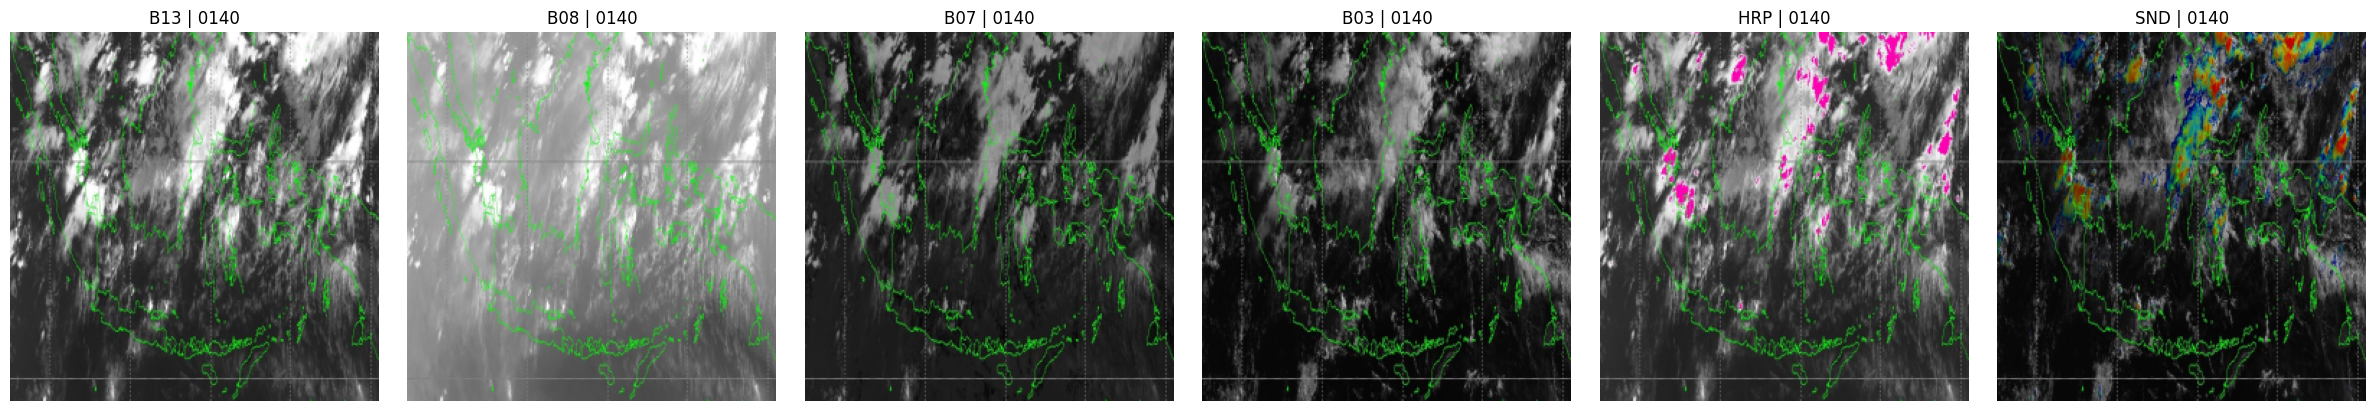

Sample time_code: 0140
Produk berhasil dicek: ['b13', 'b08', 'b07', 'b03', 'hrp', 'snd']


In [5]:

# ============================================================
# 4. QUALITY CHECK DAN PREVIEW DATASET
# ============================================================

def read_rgb(path):
    path = Path(path)
    img_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise FileNotFoundError(f"Tidak bisa membaca gambar: {path}")
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def lonlat_to_pixel(lon, lat, width, height, domain=DOMAIN_BBOX):
    """Konversi lon/lat ke piksel untuk citra r2w rectangular display.

    Ini pendekatan praktis untuk crop paper tahun pertama.
    Jika ingin presisi geospasial tinggi, gunakan data level lebih tinggi dengan georeferencing.
    """
    x = (lon - domain["lon_min"]) / (domain["lon_max"] - domain["lon_min"]) * width
    y = (domain["lat_max"] - lat) / (domain["lat_max"] - domain["lat_min"]) * height
    return int(round(x)), int(round(y))


def crop_bbox(img_rgb, bbox=INDONESIA_BBOX, domain=DOMAIN_BBOX):
    h, w = img_rgb.shape[:2]
    x1, y1 = lonlat_to_pixel(bbox["lon_min"], bbox["lat_max"], w, h, domain)
    x2, y2 = lonlat_to_pixel(bbox["lon_max"], bbox["lat_min"], w, h, domain)

    x1, x2 = sorted([max(0, x1), min(w, x2)])
    y1, y2 = sorted([max(0, y1), min(h, y2)])

    if x2 <= x1 or y2 <= y1:
        raise ValueError("BBOX crop tidak valid. Cek DOMAIN_BBOX dan INDONESIA_BBOX.")

    return img_rgb[y1:y2, x1:x2]


def resize_rgb(img_rgb, size=IMG_SIZE, interpolation=cv2.INTER_AREA):
    return cv2.resize(img_rgb, size, interpolation=interpolation)


valid_manifest = manifest[manifest["is_complete_and_valid"]].reset_index(drop=True)
if valid_manifest.empty:
    raise RuntimeError("Manifest valid kosong. Download belum berhasil.")

sample_idx = min(10, len(valid_manifest) - 1)
sample = valid_manifest.iloc[sample_idx]

fig_cols = len(DOWNLOAD_PRODUCTS)
plt.figure(figsize=(4 * fig_cols, 4))
for i, product in enumerate(DOWNLOAD_PRODUCTS):
    rgb = read_rgb(sample[product])
    cropped = crop_bbox(rgb)
    cropped = resize_rgb(cropped)
    plt.subplot(1, fig_cols, i + 1)
    plt.imshow(cropped)
    plt.title(f"{product.upper()} | {sample['time_code']}")
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Sample time_code:", sample["time_code"])
print("Produk berhasil dicek:", DOWNLOAD_PRODUCTS)


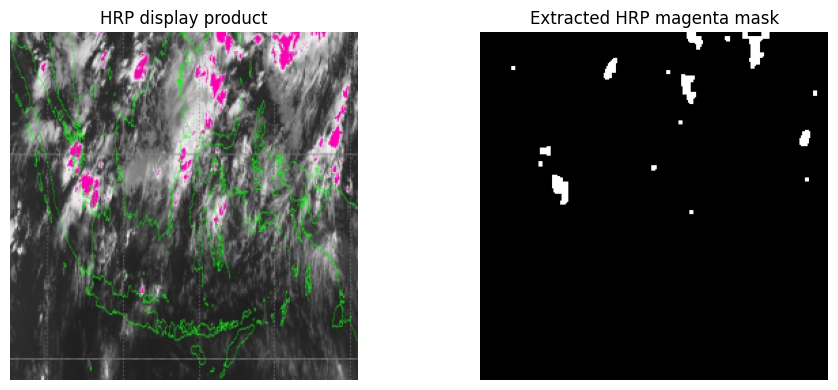

Positive pixel ratio sample: 0.0148162841796875


In [6]:

# ============================================================
# 5. EKSTRAKSI INPUT DAN LABEL HRP
# ============================================================

def product_to_input_channel(path, product):
    """Konversi citra produk JMA menjadi 1 channel float32 [0,1]."""
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    # Semua display product dikonversi ke gray untuk stabilitas awal.
    # B03 daytime dapat gelap pada malam hari; tetap dipakai sebagai informasi kanal.
    gray = cv2.cvtColor(resized, cv2.COLOR_RGB2GRAY).astype("float32") / 255.0
    return gray[..., None]


def extract_hrp_magenta_mask_from_rgb(rgb):
    """Ekstraksi pseudo-label dari HRP.

    Produk HRP menandai area potensi hujan lebat dengan magenta.
    Threshold dibuat konservatif agar garis/warna lain tidak ikut terbaca.
    """
    r = rgb[..., 0].astype(np.int16)
    g = rgb[..., 1].astype(np.int16)
    b = rgb[..., 2].astype(np.int16)

    mask = (
        (r >= 160) &
        (b >= 120) &
        (g <= 130) &
        ((r - g) >= 50) &
        ((b - g) >= 25)
    )

    mask = mask.astype(np.uint8)

    # Bersihkan noise kecil dan lubang kecil.
    kernel_open = np.ones((3, 3), np.uint8)
    kernel_close = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open, iterations=1)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close, iterations=1)

    return mask.astype("float32")


def extract_snd_proxy_mask_from_rgb(rgb):
    """Proxy mask dari SND jika diperlukan.

    Ini bukan target utama paper.
    SND hanya membantu visualisasi/validasi awan konvektif.
    """
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    s = hsv[..., 1]
    v = hsv[..., 2]
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]

    saturated = (s > 80) & (v > 60)
    coastline_green = (g > 110) & (r < 90) & (b < 100)
    mask = saturated & (~coastline_green)

    mask = mask.astype(np.uint8)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    return mask.astype("float32")


def target_to_mask(path, product=TARGET_PRODUCT):
    rgb = read_rgb(path)
    cropped = crop_bbox(rgb)
    resized = resize_rgb(cropped, IMG_SIZE)

    if product.lower() == "hrp":
        mask = extract_hrp_magenta_mask_from_rgb(resized)
    elif product.lower() == "snd":
        mask = extract_snd_proxy_mask_from_rgb(resized)
    else:
        raise ValueError("Target yang didukung hanya 'hrp' atau 'snd'.")

    return mask[..., None]


# Preview label HRP.
sample = valid_manifest.iloc[sample_idx]
hrp_rgb = resize_rgb(crop_bbox(read_rgb(sample[TARGET_PRODUCT])), IMG_SIZE)
hrp_mask = target_to_mask(sample[TARGET_PRODUCT], TARGET_PRODUCT)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(hrp_rgb)
plt.title("HRP display product")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hrp_mask[..., 0], cmap="gray")
plt.title("Extracted HRP magenta mask")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Positive pixel ratio sample:", float(hrp_mask.mean()))


In [7]:

# ============================================================
# 6. MEMBANGUN SEQUENCE SPATIOTEMPORAL
# ============================================================

def build_sequences_from_manifest(df, seq_len=SEQ_LEN, input_products=INPUT_PRODUCTS, target_product=TARGET_PRODUCT):
    """Bangun X sequence dan y mask.

    X shape: (N, T, H, W, C)
    y shape: (N, H, W, 1)
    """
    df = df[df["is_complete_and_valid"]].sort_values("time_code").reset_index(drop=True)

    if len(df) < seq_len:
        raise RuntimeError(
            f"Jumlah timestamp valid ({len(df)}) lebih kecil dari SEQ_LEN ({seq_len})."
        )

    X, y, meta_rows = [], [], []

    for end_idx in tqdm(range(seq_len - 1, len(df)), desc="Building sequences"):
        seq_df = df.iloc[end_idx - seq_len + 1:end_idx + 1]
        target_row = df.iloc[end_idx]

        frames = []
        for _, row in seq_df.iterrows():
            channels = []
            for product in input_products:
                channels.append(product_to_input_channel(row[product], product))
            frame = np.concatenate(channels, axis=-1)
            frames.append(frame)

        target_mask = target_to_mask(target_row[target_product], product=target_product)

        X.append(np.stack(frames, axis=0))
        y.append(target_mask)
        meta_rows.append({
            "sequence_time_codes": ",".join(seq_df["time_code"].tolist()),
            "target_time_code": target_row["time_code"],
            "target_path": target_row[target_product],
        })

    X = np.asarray(X, dtype="float32")
    y = np.asarray(y, dtype="float32")
    meta = pd.DataFrame(meta_rows)

    return X, y, meta


X, y, meta = build_sequences_from_manifest(valid_manifest)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Overall positive pixel ratio:", float(y.mean()))
display(meta.head())

# Simpan metadata sequence untuk reproducibility.
meta_path = OUTPUT_DIR / "sequence_metadata.csv"
meta.to_csv(meta_path, index=False)
print("Sequence metadata saved:", meta_path)

# Guard: data positif terlalu sedikit membuat training tidak stabil.
if y.mean() < 0.001:
    print("PERINGATAN: Rasio pixel positif sangat rendah. Pertimbangkan tambah hari/kasus hujan lebat atau pakai class balancing.")


Building sequences:   0%|          | 0/139 [00:00<?, ?it/s]

X shape: (139, 4, 256, 256, 4)
y shape: (139, 256, 256, 1)
Overall positive pixel ratio: 0.020405063405632973


,sequence_time_codes,target_time_code,target_path
0,"0000,0010,0020,0030",0030,dataset_himawari_r2w\raw\jma_snapshot_20260527...
1,"0010,0020,0030,0040",0040,dataset_himawari_r2w\raw\jma_snapshot_20260527...
2,"0020,0030,0040,0050",0050,dataset_himawari_r2w\raw\jma_snapshot_20260527...
3,"0030,0040,0050,0100",0100,dataset_himawari_r2w\raw\jma_snapshot_20260527...
4,"0040,0050,0100,0110",0110,dataset_himawari_r2w\raw\jma_snapshot_20260527...


Sequence metadata saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\sequence_metadata.csv


In [8]:

# ============================================================
# 7. SPLIT DATA TRAIN/VALIDATION/TEST BERBASIS WAKTU
# ============================================================

def temporal_split(X, y, meta, train_ratio=0.70, val_ratio=0.15):
    n = len(X)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))

    X_train, y_train = X[:train_end], y[:train_end]
    X_val, y_val = X[train_end:val_end], y[train_end:val_end]
    X_test, y_test = X[val_end:], y[val_end:]

    meta_train = meta.iloc[:train_end].reset_index(drop=True)
    meta_val = meta.iloc[train_end:val_end].reset_index(drop=True)
    meta_test = meta.iloc[val_end:].reset_index(drop=True)

    if len(X_train) == 0 or len(X_val) == 0 or len(X_test) == 0:
        raise RuntimeError(
            "Split menghasilkan train/val/test kosong. Tambah data atau kurangi SEQ_LEN."
        )

    return (X_train, y_train, meta_train), (X_val, y_val, meta_val), (X_test, y_test, meta_test)


(train_data, val_data, test_data) = temporal_split(X, y, meta)
X_train, y_train, meta_train = train_data
X_val, y_val, meta_val = val_data
X_test, y_test, meta_test = test_data

print("Train:", X_train.shape, y_train.shape, "positive:", float(y_train.mean()))
print("Val  :", X_val.shape, y_val.shape, "positive:", float(y_val.mean()))
print("Test :", X_test.shape, y_test.shape, "positive:", float(y_test.mean()))

split_summary = pd.DataFrame([
    {"split": "train", "n": len(X_train), "positive_pixel_ratio": float(y_train.mean())},
    {"split": "validation", "n": len(X_val), "positive_pixel_ratio": float(y_val.mean())},
    {"split": "test", "n": len(X_test), "positive_pixel_ratio": float(y_test.mean())},
])
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)


Train: (97, 4, 256, 256, 4) (97, 256, 256, 1) positive: 0.01829969324171543
Val  : (21, 4, 256, 256, 4) (21, 256, 256, 1) positive: 0.02546183206140995
Test : (21, 4, 256, 256, 4) (21, 256, 256, 1) positive: 0.0250730961561203


,split,n,positive_pixel_ratio
0,train,97,0.018300
1,validation,21,0.025462
2,test,21,0.025073


In [9]:

# ============================================================
# 8. DATA AUGMENTATION DAN TF.DATA PIPELINE
# ============================================================

def augment_sequence_and_mask(x, y):
    """Augmentasi ringan yang menjaga sinkronisasi sequence dan mask."""
    # Flip horizontal.
    if tf.random.uniform(()) > 0.5:
        x = tf.reverse(x, axis=[2])  # width axis pada (T,H,W,C)
        y = tf.reverse(y, axis=[1])  # width axis pada (H,W,C)

    # Flip vertical.
    if tf.random.uniform(()) > 0.5:
        x = tf.reverse(x, axis=[1])  # height axis
        y = tf.reverse(y, axis=[0])  # height axis

    # Brightness/contrast untuk input saja.
    delta = tf.random.uniform((), minval=-0.04, maxval=0.04)
    x = tf.clip_by_value(x + delta, 0.0, 1.0)

    contrast = tf.random.uniform((), minval=0.95, maxval=1.05)
    x = tf.clip_by_value((x - 0.5) * contrast + 0.5, 0.0, 1.0)

    return x, y


def make_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(X_arr), 512), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(augment_sequence_and_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, y_train, shuffle=True, augment=True)
val_ds = make_dataset(X_val, y_val, shuffle=False, augment=False)
test_ds = make_dataset(X_test, y_test, shuffle=False, augment=False)

print("tf.data pipeline siap.")


tf.data pipeline siap.


In [10]:

# ============================================================
# 9. LOSS DAN METRICS UNTUK SEGMENTASI
# ============================================================

SMOOTH = 1e-6

def dice_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    denom = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    return (2.0 * inter + SMOOTH) / (denom + SMOOTH)


def iou_coef(y_true, y_pred):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])
    inter = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - inter
    return (inter + SMOOTH) / (union + SMOOTH)


def tversky_index(y_true, y_pred, alpha=0.7, beta=0.3):
    y_true_f = tf.reshape(tf.cast(y_true, tf.float32), [-1])
    y_pred_f = tf.reshape(tf.cast(y_pred, tf.float32), [-1])

    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1 - y_pred_f))

    return (tp + SMOOTH) / (tp + alpha * fp + beta * fn + SMOOTH)


def focal_tversky_loss(y_true, y_pred, gamma=0.75):
    tv = tversky_index(y_true, y_pred)
    return tf.pow((1.0 - tv), gamma)


def bce_focal_tversky_loss(y_true, y_pred):
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    return tf.reduce_mean(bce) + focal_tversky_loss(y_true, y_pred)


def binary_precision_metric(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fp = tf.reduce_sum((1 - y_true) * y_pred_bin)
    return (tp + SMOOTH) / (tp + fp + SMOOTH)


def binary_recall_metric(y_true, y_pred):
    y_pred_bin = tf.cast(y_pred >= 0.5, tf.float32)
    tp = tf.reduce_sum(y_true * y_pred_bin)
    fn = tf.reduce_sum(y_true * (1 - y_pred_bin))
    return (tp + SMOOTH) / (tp + fn + SMOOTH)


CUSTOM_OBJECTS = {
    "dice_coef": dice_coef,
    "iou_coef": iou_coef,
    "binary_precision_metric": binary_precision_metric,
    "binary_recall_metric": binary_recall_metric,
    "bce_focal_tversky_loss": bce_focal_tversky_loss,
}


In [11]:

# ============================================================
# 10. MODEL UTAMA: ST-HRPNet v1
# ============================================================

def td_conv_block(x, filters, name):
    x = layers.TimeDistributed(
        layers.SeparableConv2D(filters, 3, padding="same", use_bias=False),
        name=f"{name}_sepconv1"
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_bn1")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_relu1")(x)

    x = layers.TimeDistributed(
        layers.SeparableConv2D(filters, 3, padding="same", use_bias=False),
        name=f"{name}_sepconv2"
    )(x)
    x = layers.TimeDistributed(layers.BatchNormalization(), name=f"{name}_bn2")(x)
    x = layers.TimeDistributed(layers.Activation("relu"), name=f"{name}_relu2")(x)
    return x


def conv_block_2d(x, filters, name):
    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_sepconv1")(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False, name=f"{name}_sepconv2")(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)
    return x


def last_time_step(x):
    return x[:, -1, ...]


def build_st_hrpnet_v1(seq_len=SEQ_LEN, img_size=IMG_SIZE, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    inputs = keras.Input(shape=(seq_len, img_size[1], img_size[0], n_channels), name="himawari_sequence")

    # Spatiotemporal encoder.
    x1 = td_conv_block(inputs, base, "enc1")
    p1 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool1")(x1)

    x2 = td_conv_block(p1, base * 2, "enc2")
    p2 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool2")(x2)

    x3 = td_conv_block(p2, base * 4, "enc3")
    p3 = layers.TimeDistributed(layers.MaxPooling2D((2, 2)), name="pool3")(x3)

    # ConvLSTM bottleneck untuk menangkap evolusi awan.
    b = layers.ConvLSTM2D(
        base * 8, 3,
        padding="same",
        return_sequences=False,
        dropout=0.15,
        recurrent_dropout=0.0,
        name="conv_lstm_bottleneck"
    )(p3)
    b = layers.BatchNormalization(name="bottleneck_bn")(b)
    b = layers.Activation("relu", name="bottleneck_relu")(b)

    # Skip dari frame terakhir agar batas spasial tetap tajam.
    s3 = layers.Lambda(last_time_step, name="skip3_last")(x3)
    s2 = layers.Lambda(last_time_step, name="skip2_last")(x2)
    s1 = layers.Lambda(last_time_step, name="skip1_last")(x1)

    # Decoder.
    u3 = layers.UpSampling2D((2, 2), name="up3")(b)
    u3 = layers.Concatenate(name="cat3")([u3, s3])
    d3 = conv_block_2d(u3, base * 4, "dec3")

    u2 = layers.UpSampling2D((2, 2), name="up2")(d3)
    u2 = layers.Concatenate(name="cat2")([u2, s2])
    d2 = conv_block_2d(u2, base * 2, "dec2")

    u1 = layers.UpSampling2D((2, 2), name="up1")(d2)
    u1 = layers.Concatenate(name="cat1")([u1, s1])
    d1 = conv_block_2d(u1, base, "dec1")

    outputs = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)

    return keras.Model(inputs, outputs, name="ST_HRPNet_v1")


def compile_seg_model(model, lr=LEARNING_RATE):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=bce_focal_tversky_loss,
        metrics=[dice_coef, iou_coef, binary_precision_metric, binary_recall_metric]
    )
    return model


st_model = compile_seg_model(build_st_hrpnet_v1())
st_model.summary()


Model: "ST_HRPNet_v1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 himawari_sequence (InputLa  [(None, 4, 256, 256, 4)]     0         []                            
 yer)                                                                                             
                                                                                                  
 enc1_sepconv1 (TimeDistrib  (None, 4, 256, 256, 32)      164       ['himawari_sequence[0][0]']   
 uted)                                                                                            
                                                                                                  
 enc1_bn1 (TimeDistributed)  (None, 4, 256, 256, 32)      128       ['enc1_sepconv1[0][0]']       
                                                                                       

In [12]:

# ============================================================
# 11. BASELINE MODELS UNTUK PAPER
# ============================================================

def build_unet2d_baseline(img_size=IMG_SIZE, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    """Baseline 1: U-Net 2D dari frame terakhir saja."""
    inp = keras.Input(shape=(img_size[1], img_size[0], n_channels), name="last_frame")

    c1 = conv_block_2d(inp, base, "u_enc1")
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block_2d(p1, base * 2, "u_enc2")
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block_2d(p2, base * 4, "u_enc3")
    p3 = layers.MaxPooling2D((2, 2))(c3)

    b = conv_block_2d(p3, base * 8, "u_bottleneck")

    u3 = layers.UpSampling2D((2, 2))(b)
    u3 = layers.Concatenate()([u3, c3])
    d3 = conv_block_2d(u3, base * 4, "u_dec3")

    u2 = layers.UpSampling2D((2, 2))(d3)
    u2 = layers.Concatenate()([u2, c2])
    d2 = conv_block_2d(u2, base * 2, "u_dec2")

    u1 = layers.UpSampling2D((2, 2))(d2)
    u1 = layers.Concatenate()([u1, c1])
    d1 = conv_block_2d(u1, base, "u_dec1")

    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(d1)
    return keras.Model(inp, out, name="UNet2D_LastFrame_Baseline")


def build_convlstm_simple_baseline(seq_len=SEQ_LEN, img_size=IMG_SIZE, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    """Baseline 2: ConvLSTM sederhana tanpa encoder-decoder skip."""
    inp = keras.Input(shape=(seq_len, img_size[1], img_size[0], n_channels), name="sequence")

    x = layers.ConvLSTM2D(base, 3, padding="same", return_sequences=True, name="clstm1")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ConvLSTM2D(base * 2, 3, padding="same", return_sequences=False, name="clstm2")(x)
    x = layers.BatchNormalization()(x)
    x = conv_block_2d(x, base * 2, "clstm_conv")
    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(x)

    return keras.Model(inp, out, name="ConvLSTM_Simple_Baseline")


def build_3dcnn_baseline(seq_len=SEQ_LEN, img_size=IMG_SIZE, n_channels=len(INPUT_PRODUCTS), base=BASE_FILTERS):
    """Baseline 3: 3D-CNN ringan untuk sequence."""
    inp = keras.Input(shape=(seq_len, img_size[1], img_size[0], n_channels), name="sequence")

    x = layers.Conv3D(base, (3, 3, 3), padding="same", activation="relu", name="conv3d_1")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Conv3D(base, (3, 3, 3), padding="same", activation="relu", name="conv3d_2")(x)
    x = layers.BatchNormalization()(x)

    # Ambil fitur temporal rata-rata.
    x = layers.Lambda(lambda z: tf.reduce_mean(z, axis=1), name="temporal_average")(x)

    x = conv_block_2d(x, base * 2, "cnn3d_refine1")
    x = conv_block_2d(x, base, "cnn3d_refine2")
    out = layers.Conv2D(1, 1, activation="sigmoid", name="hrp_mask")(x)

    return keras.Model(inp, out, name="CNN3D_Baseline")


print("Baseline builders ready.")


Baseline builders ready.


In [13]:
# ============================================================
# 12. TRAINING FUNCTION
# ============================================================

def train_model(model, train_data, val_data, name, epochs):
    model_dir = OUTPUT_DIR / name
    model_dir.mkdir(parents=True, exist_ok=True)

    callbacks = [
        keras.callbacks.ModelCheckpoint(
            str(model_dir / f"{name}_best.weights.h5"),
            monitor="val_iou_coef",
            mode="max",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_iou_coef",
            mode="max",
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=1
        ),
        keras.callbacks.CSVLogger(str(model_dir / f"{name}_training_log.csv"))
    ]

    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1
    )

    hist_df = pd.DataFrame(history.history)
    hist_df.to_csv(model_dir / f"{name}_history.csv", index=False)

    return model, hist_df, model_dir


st_model, st_history, st_model_dir = train_model(
    st_model,
    train_ds,
    val_ds,
    name="ST_HRPNet_v1",
    epochs=EPOCHS_MAIN
)

print("Training ST-HRPNet v1 selesai.")

Epoch 1/50
25/25 [==============================] - ETA: 0s - loss: 1.3582 - dice_coef: 0.0788 - iou_coef: 0.0412 - binary_precision_metric: 0.2594 - binary_recall_metric: 0.7832
Epoch 1: val_iou_coef improved from -inf to 0.02501, saving model to outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\ST_HRPNet_v1\ST_HRPNet_v1_best.weights.h5
25/25 [==============================] - 67s 2s/step - loss: 1.3582 - dice_coef: 0.0788 - iou_coef: 0.0412 - binary_precision_metric: 0.2594 - binary_recall_metric: 0.7832 - val_loss: 1.6139 - val_dice_coef: 0.0488 - val_iou_coef: 0.0250 - val_binary_precision_metric: 1.0000 - val_binary_recall_metric: 2.1825e-10 - lr: 0.0010
Epoch 2/50
25/25 [==============================] - ETA: 0s - loss: 1.1182 - dice_coef: 0.1392 - iou_coef: 0.0753 - binary_precision_metric: 0.4636 - binary_recall_metric: 0.8430
Epoch 2: val_iou_coef did not improve from 0.02501
25/25 [==============================] - 61s 2s/step - loss: 1.1182 - dice_coef: 0

In [14]:

# ============================================================
# 13. TRAINING BASELINE COMPARISON
# ============================================================

baseline_models = {}

if RUN_BASELINES:
    # Baseline U-Net 2D memakai frame terakhir.
    X_train_last = X_train[:, -1, ...]
    X_val_last = X_val[:, -1, ...]
    X_test_last = X_test[:, -1, ...]

    def make_2d_dataset(X_arr, y_arr, batch_size=BATCH_SIZE, shuffle=False):
        ds = tf.data.Dataset.from_tensor_slices((X_arr, y_arr))
        if shuffle:
            ds = ds.shuffle(buffer_size=min(len(X_arr), 512), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
        return ds

    train_2d_ds = make_2d_dataset(X_train_last, y_train, shuffle=True)
    val_2d_ds = make_2d_dataset(X_val_last, y_val, shuffle=False)

    unet_model = compile_seg_model(build_unet2d_baseline())
    unet_model, unet_hist, unet_dir = train_model(
        unet_model,
        train_2d_ds,
        val_2d_ds,
        name="UNet2D_LastFrame_Baseline",
        epochs=EPOCHS_BASELINE
    )
    baseline_models["UNet2D_LastFrame_Baseline"] = {
        "model": unet_model,
        "input_type": "2d_last_frame"
    }

    convlstm_base = compile_seg_model(build_convlstm_simple_baseline())
    convlstm_base, convlstm_hist, convlstm_dir = train_model(
        convlstm_base,
        train_ds,
        val_ds,
        name="ConvLSTM_Simple_Baseline",
        epochs=EPOCHS_BASELINE
    )
    baseline_models["ConvLSTM_Simple_Baseline"] = {
        "model": convlstm_base,
        "input_type": "sequence"
    }

    cnn3d_base = compile_seg_model(build_3dcnn_baseline())
    cnn3d_base, cnn3d_hist, cnn3d_dir = train_model(
        cnn3d_base,
        train_ds,
        val_ds,
        name="CNN3D_Baseline",
        epochs=EPOCHS_BASELINE
    )
    baseline_models["CNN3D_Baseline"] = {
        "model": cnn3d_base,
        "input_type": "sequence"
    }

else:
    print("RUN_BASELINES = False, baseline training dilewati.")


Epoch 1/30
25/25 [==============================] - ETA: 0s - loss: 1.2866 - dice_coef: 0.0814 - iou_coef: 0.0429 - binary_precision_metric: 0.2291 - binary_recall_metric: 0.5850
Epoch 1: val_iou_coef improved from -inf to 0.02498, saving model to outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\UNet2D_LastFrame_Baseline\UNet2D_LastFrame_Baseline_best.weights.h5
25/25 [==============================] - 28s 934ms/step - loss: 1.2866 - dice_coef: 0.0814 - iou_coef: 0.0429 - binary_precision_metric: 0.2291 - binary_recall_metric: 0.5850 - val_loss: 1.5924 - val_dice_coef: 0.0487 - val_iou_coef: 0.0250 - val_binary_precision_metric: 1.0000 - val_binary_recall_metric: 2.1825e-10 - lr: 0.0010
Epoch 2/30
25/25 [==============================] - ETA: 0s - loss: 1.0131 - dice_coef: 0.2035 - iou_coef: 0.1146 - binary_precision_metric: 0.5080 - binary_recall_metric: 0.8648
Epoch 2: val_iou_coef did not improve from 0.02498
25/25 [==============================] - 22s 894ms/st

In [18]:

# ============================================================
# 14. EVALUASI: THRESHOLD OPTIMIZATION, IoU, Dice, PR-AUC, INFERENCE TIME
# ============================================================

def predict_model(model, input_type="sequence", batch_size=BATCH_SIZE):
    if input_type == "2d_last_frame":
        return model.predict(X_test[:, -1, ...], batch_size=batch_size, verbose=1)
    return model.predict(X_test, batch_size=batch_size, verbose=1)


def predict_val_model(model, input_type="sequence", batch_size=BATCH_SIZE):
    if input_type == "2d_last_frame":
        return model.predict(X_val[:, -1, ...], batch_size=batch_size, verbose=0)
    return model.predict(X_val, batch_size=batch_size, verbose=0)


def binary_metrics_np(y_true, y_prob, threshold=0.5):
    yt = (y_true.reshape(-1) >= 0.5).astype(np.uint8)
    yp = (y_prob.reshape(-1) >= threshold).astype(np.uint8)

    tp = np.sum((yt == 1) & (yp == 1))
    fp = np.sum((yt == 0) & (yp == 1))
    fn = np.sum((yt == 1) & (yp == 0))
    tn = np.sum((yt == 0) & (yp == 0))

    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    dice = 2 * tp / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-7)

    return {
        "threshold": threshold,
        "iou": iou,
        "dice_f1": dice,
        "precision": precision,
        "recall": recall,
        "accuracy": accuracy,
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }


def find_best_threshold(y_true, y_prob, metric="iou"):
    thresholds = np.arange(0.10, 0.91, 0.02)
    rows = []
    for th in thresholds:
        rows.append(binary_metrics_np(y_true, y_prob, threshold=float(th)))
    df = pd.DataFrame(rows)
    best_idx = df[metric].idxmax()
    return float(df.loc[best_idx, "threshold"]), df


def pr_auc_score_np(y_true, y_prob):
    yt = (y_true.reshape(-1) >= 0.5).astype(np.uint8)
    yp = y_prob.reshape(-1).astype(np.float32)

    # Jika hanya satu kelas, PR curve tidak stabil.
    if len(np.unique(yt)) < 2:
        return np.nan

    precision, recall, _ = precision_recall_curve(yt, yp)
    return auc(recall, precision)


def measure_inference_time(model, input_type="sequence", n_repeat=5):
    if input_type == "2d_last_frame":
        arr = X_test[:min(len(X_test), BATCH_SIZE), -1, ...]
    else:
        arr = X_test[:min(len(X_test), BATCH_SIZE)]

    # warm-up
    _ = model.predict(arr, verbose=0)

    times = []
    for _ in range(n_repeat):
        start = time.time()
        _ = model.predict(arr, verbose=0)
        elapsed = time.time() - start
        times.append(elapsed / len(arr))
    return float(np.mean(times)), float(np.std(times))


evaluation_rows = []

models_to_eval = {
    "ST_HRPNet_v1": {
        "model": st_model,
        "input_type": "sequence"
    }
}
models_to_eval.update(baseline_models)

for model_name, obj in models_to_eval.items():
    print(f"Evaluating: {model_name}")
    model_obj = obj["model"]
    input_type = obj["input_type"]

    val_prob = predict_val_model(model_obj, input_type=input_type)
    best_th, th_df = find_best_threshold(y_val, val_prob, metric="iou")
    th_df.to_csv(OUTPUT_DIR / f"{model_name}_threshold_search_val.csv", index=False)

    test_prob = predict_model(model_obj, input_type=input_type)
    metrics = binary_metrics_np(y_test, test_prob, threshold=best_th)
    metrics["model"] = model_name
    metrics["pr_auc"] = pr_auc_score_np(y_test, test_prob)

    inf_mean, inf_std = measure_inference_time(model_obj, input_type=input_type)
    metrics["inference_sec_per_sample_mean"] = inf_mean
    metrics["inference_sec_per_sample_std"] = inf_std

    evaluation_rows.append(metrics)

results_df = pd.DataFrame(evaluation_rows)
cols = ["model", "threshold", "iou", "dice_f1", "precision", "recall", "accuracy", "pr_auc",
        "inference_sec_per_sample_mean", "inference_sec_per_sample_std", "tp", "fp", "fn", "tn"]
results_df = results_df[cols]
results_df = results_df.sort_values("iou", ascending=False).reset_index(drop=True)

results_path = OUTPUT_DIR / "paper_ready_model_comparison_results.csv"
results_df.to_csv(results_path, index=False)

display(results_df)
print("Results saved:", results_path)


Evaluating: ST_HRPNet_v1
6/6 [==============================] - 3s 503ms/step
Evaluating: UNet2D_LastFrame_Baseline
6/6 [==============================] - 1s 155ms/step
Evaluating: ConvLSTM_Simple_Baseline
6/6 [==============================] - 10s 2s/step
Evaluating: CNN3D_Baseline
6/6 [==============================] - 2s 306ms/step


,model,threshold,iou,dice_f1,precision,recall,accuracy,pr_auc,inference_sec_per_sample_mean,inference_sec_per_sample_std,tp,fp,fn,tn
0,ST_HRPNet_v1,0.1,0.025073,0.04892,0.025073,1.0,0.025073,0.037265,0.166604,0.004512,34507,1341749,0,0
1,UNet2D_LastFrame_Baseline,0.1,0.025073,0.04892,0.025073,1.0,0.025073,0.020550,0.055031,0.001483,34507,1341749,0,0
2,ConvLSTM_Simple_Baseline,0.1,0.025073,0.04892,0.025073,1.0,0.025073,0.015102,0.501911,0.005769,34507,1341749,0,0
3,CNN3D_Baseline,0.1,0.025073,0.04892,0.025073,1.0,0.025073,0.080600,0.105122,0.001196,34507,1341749,0,0


Results saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\paper_ready_model_comparison_results.csv


Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\prediction_visual_000.png


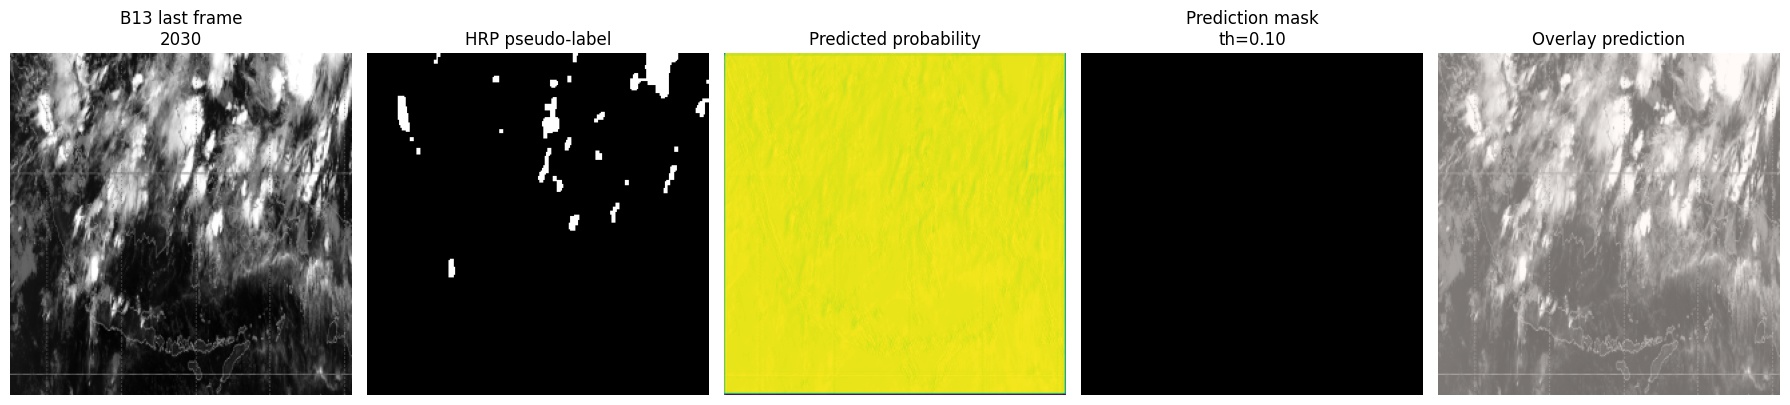

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\prediction_visual_001.png


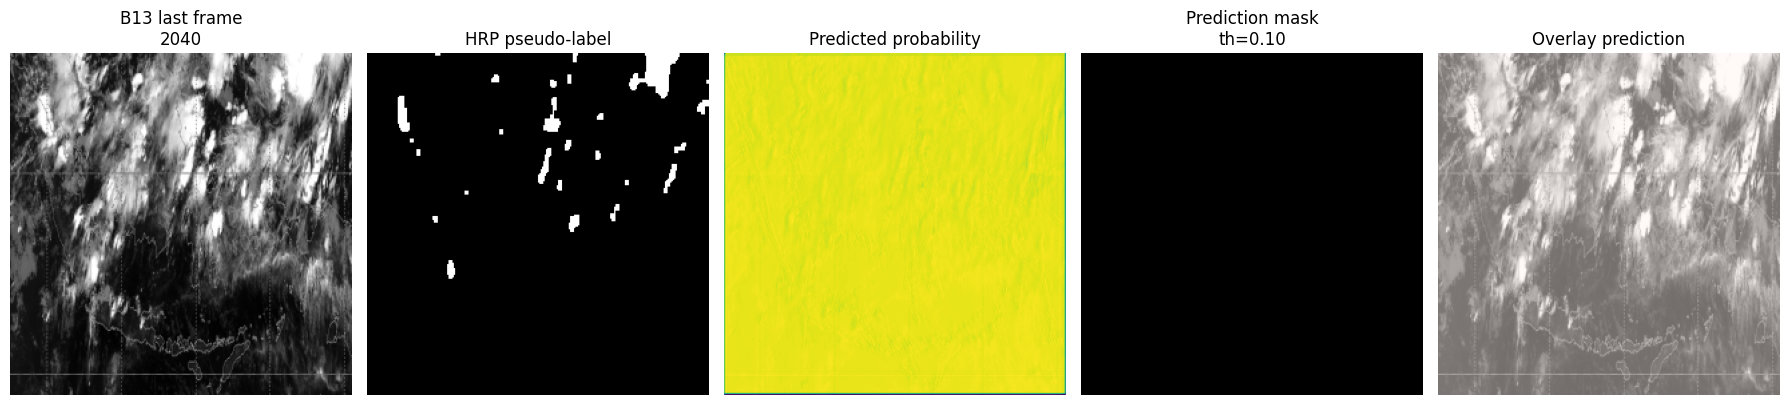

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\prediction_visual_002.png


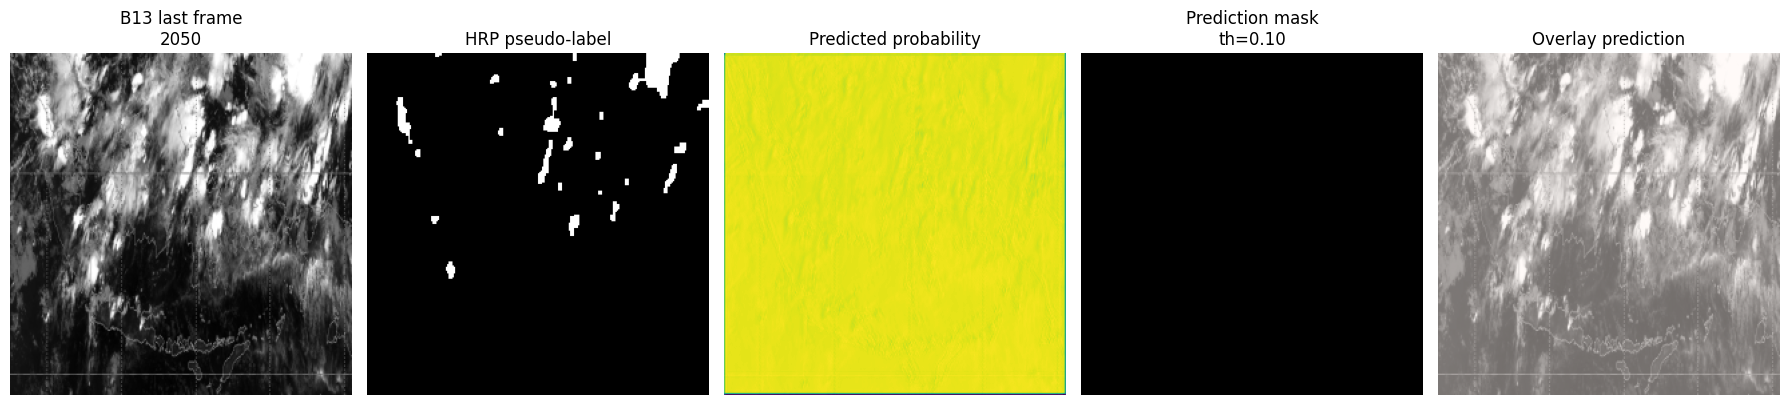

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\prediction_visual_003.png


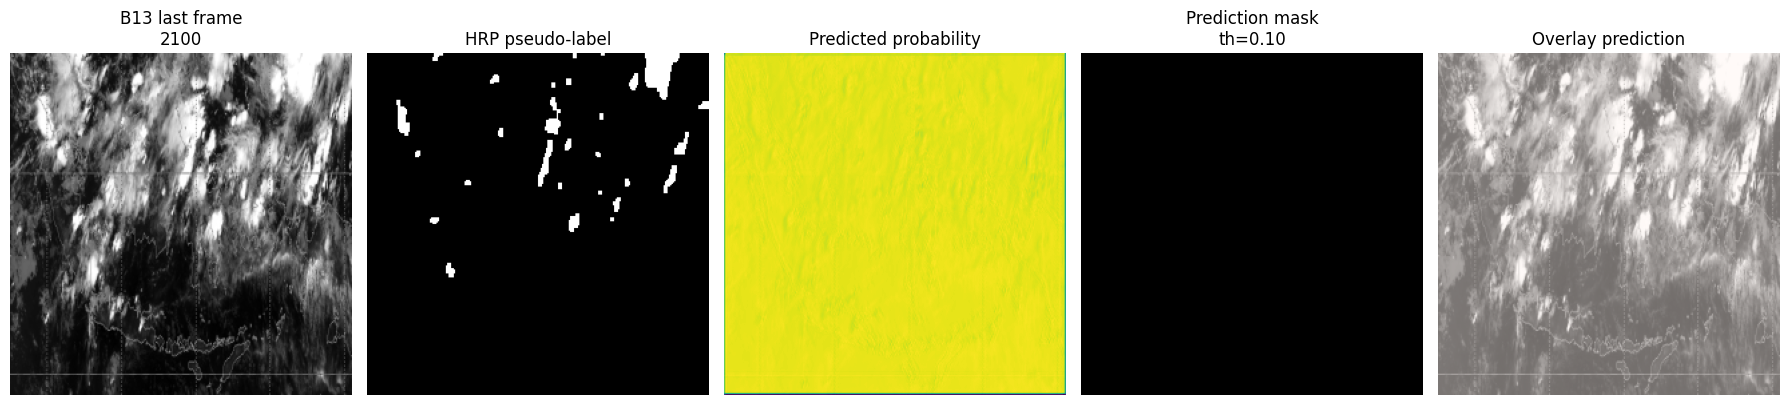

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\prediction_visual_004.png


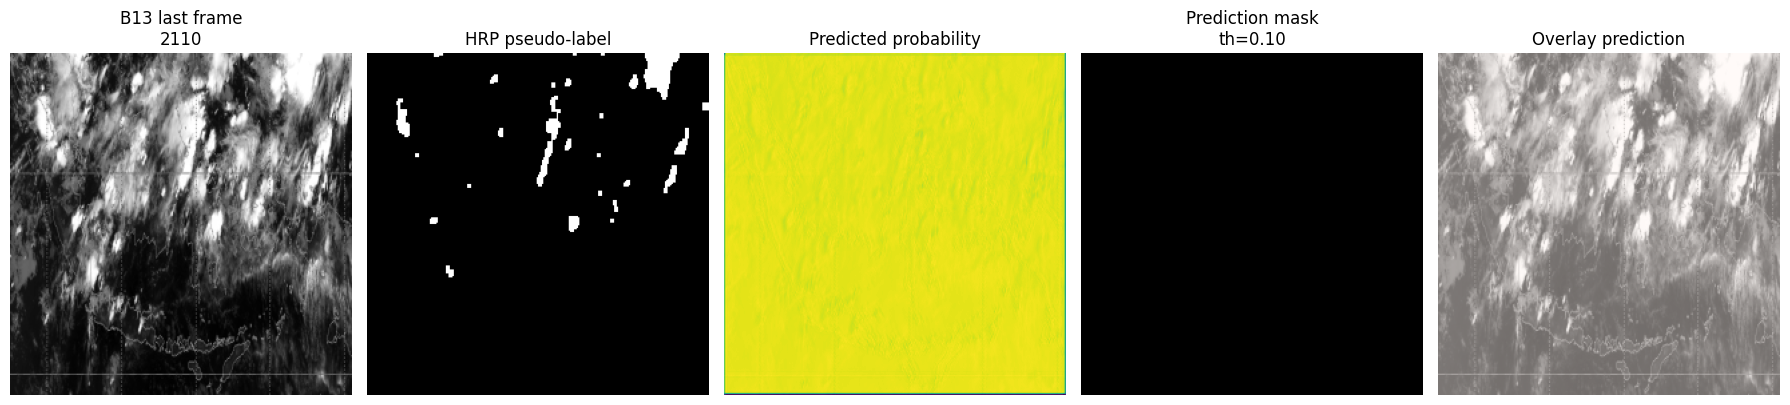

Saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\prediction_visual_005.png


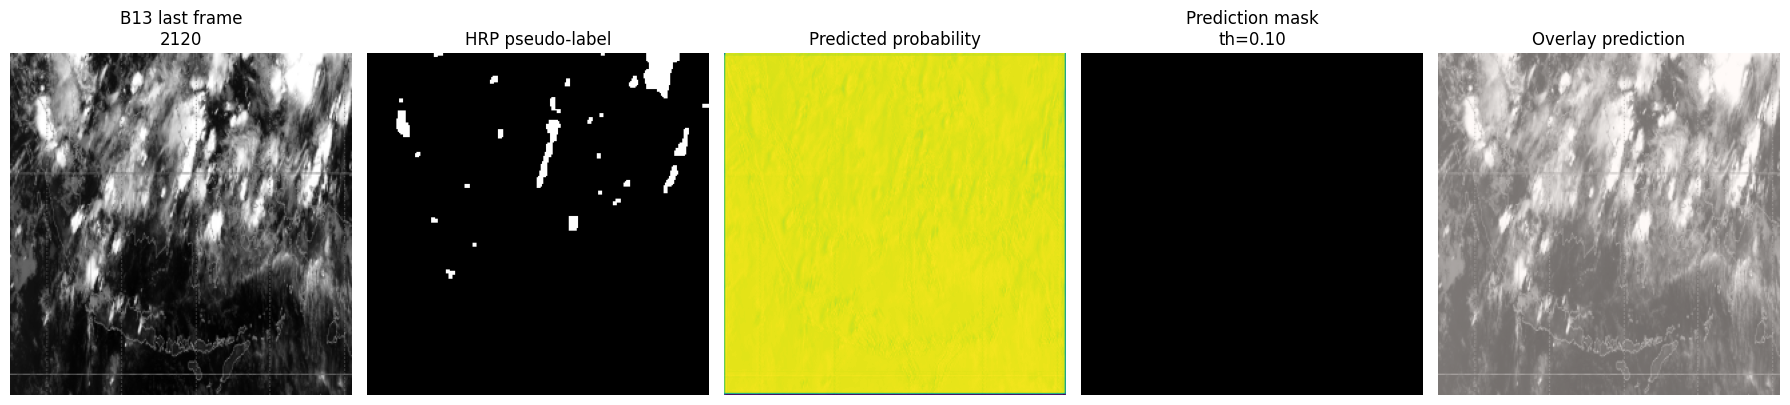

In [19]:

# ============================================================
# 15. VISUALISASI HASIL PREDIKSI MODEL UTAMA
# ============================================================

def get_best_threshold_for_model(model_name="ST_HRPNet_v1"):
    row = results_df[results_df["model"] == model_name]
    if row.empty:
        return 0.5
    return float(row.iloc[0]["threshold"])


def visualize_prediction(idx=0, model_obj=st_model, threshold=None, save=True):
    if threshold is None:
        threshold = get_best_threshold_for_model("ST_HRPNet_v1")

    idx = int(min(max(idx, 0), len(X_test) - 1))

    prob = model_obj.predict(X_test[idx:idx+1], verbose=0)[0, ..., 0]
    pred = (prob >= threshold).astype(np.float32)

    # Input B13 frame terakhir.
    last_b13 = X_test[idx, -1, ..., INPUT_PRODUCTS.index("b13")]
    gt = y_test[idx, ..., 0]

    fig = plt.figure(figsize=(18, 4))

    plt.subplot(1, 5, 1)
    plt.imshow(last_b13, cmap="gray")
    plt.title(f"B13 last frame\n{meta_test.iloc[idx]['target_time_code']}")
    plt.axis("off")

    plt.subplot(1, 5, 2)
    plt.imshow(gt, cmap="gray")
    plt.title("HRP pseudo-label")
    plt.axis("off")

    plt.subplot(1, 5, 3)
    plt.imshow(prob, cmap="viridis")
    plt.title("Predicted probability")
    plt.axis("off")

    plt.subplot(1, 5, 4)
    plt.imshow(pred, cmap="gray")
    plt.title(f"Prediction mask\nth={threshold:.2f}")
    plt.axis("off")

    plt.subplot(1, 5, 5)
    plt.imshow(last_b13, cmap="gray")
    plt.imshow(pred, alpha=0.45, cmap="Reds")
    plt.title("Overlay prediction")
    plt.axis("off")

    plt.tight_layout()

    if save:
        out_path = OUTPUT_DIR / f"prediction_visual_{idx:03d}.png"
        fig.savefig(out_path, dpi=200, bbox_inches="tight")
        print("Saved:", out_path)

    plt.show()


for i in range(min(6, len(X_test))):
    visualize_prediction(i, st_model)


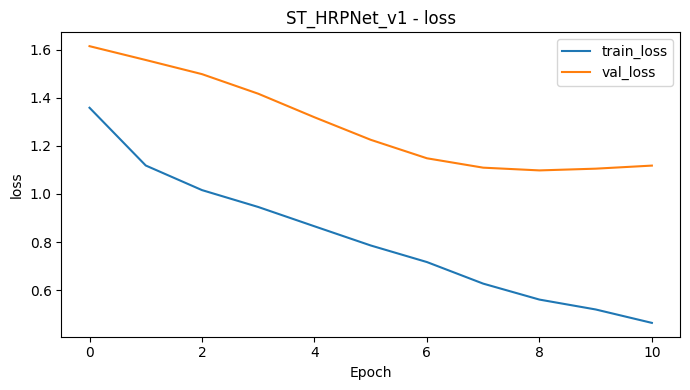

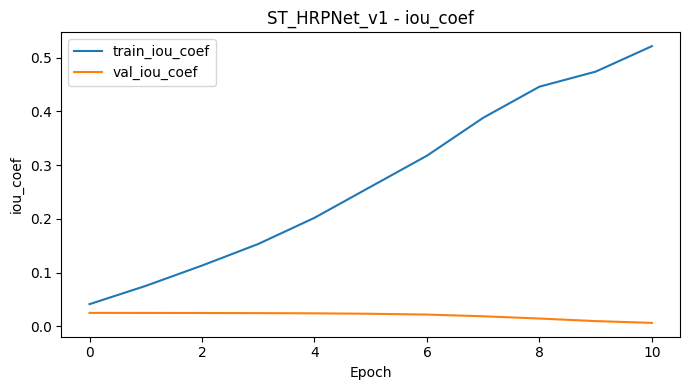

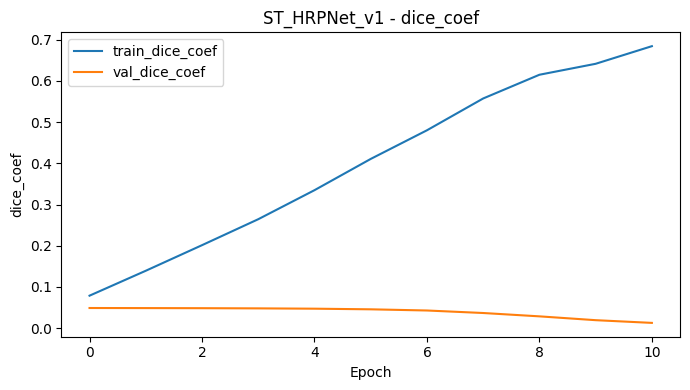

Experiment summary saved: outputs\ST_HRPNet_v1_Himawari_Indonesia\jma_snapshot_20260527_1028UTC\experiment_summary.json
{
  "paper_title": "ST-HRPNet v1: A ConvLSTM Encoder\u2013Decoder Architecture for Spatiotemporal Segmentation of Himawari-Derived Heavy Rainfall Potential Areas over Indonesia",
  "project_name": "ST_HRPNet_v1_Himawari_Indonesia",
  "dataset_tag": "jma_snapshot_20260527_1028UTC",
  "jma_list_url": "https://www.data.jma.go.jp/mscweb/data/himawari/list_r2w.html",
  "input_products": [
    "b13",
    "b08",
    "b07",
    "b03"
  ],
  "target_product": "hrp",
  "optional_products_downloaded": [
    "snd"
  ],
  "download_products": [
    "b13",
    "b08",
    "b07",
    "b03",
    "hrp",
    "snd"
  ],
  "sequence_length": 4,
  "image_size": [
    256,
    256
  ],
  "domain_bbox": {
    "lon_min": 90.0,
    "lon_max": 165.0,
    "lat_max": 30.0,
    "lat_min": -15.0
  },
  "indonesia_bbox": {
    "lon_min": 95.0,
    "lon_max": 141.0,
    "lat_max": 6.0,
    "lat_min":

In [20]:

# ============================================================
# 16. GRAFIK TRAINING HISTORY DAN EXPORT RINGKASAN EKSPERIMEN
# ============================================================

def plot_history(history_df, model_name):
    metrics_to_plot = ["loss", "iou_coef", "dice_coef"]
    for metric in metrics_to_plot:
        if metric not in history_df.columns:
            continue
        plt.figure(figsize=(7, 4))
        plt.plot(history_df[metric], label=f"train_{metric}")
        val_metric = f"val_{metric}"
        if val_metric in history_df.columns:
            plt.plot(history_df[val_metric], label=val_metric)
        plt.title(f"{model_name} - {metric}")
        plt.xlabel("Epoch")
        plt.ylabel(metric)
        plt.legend()
        plt.tight_layout()
        out_path = OUTPUT_DIR / f"{model_name}_{metric}_curve.png"
        plt.savefig(out_path, dpi=200, bbox_inches="tight")
        plt.show()

plot_history(st_history, "ST_HRPNet_v1")

experiment_summary = {
    "paper_title": PAPER_TITLE,
    "project_name": PROJECT_NAME,
    "dataset_tag": DATASET_TAG,
    "jma_list_url": JMA_LIST_URL,
    "input_products": INPUT_PRODUCTS,
    "target_product": TARGET_PRODUCT,
    "optional_products_downloaded": OPTIONAL_PRODUCTS,
    "download_products": DOWNLOAD_PRODUCTS,
    "sequence_length": SEQ_LEN,
    "image_size": IMG_SIZE,
    "domain_bbox": DOMAIN_BBOX,
    "indonesia_bbox": INDONESIA_BBOX,
    "n_raw_timestamps_valid": int(len(valid_manifest)),
    "n_sequences": int(len(X)),
    "train_sequences": int(len(X_train)),
    "val_sequences": int(len(X_val)),
    "test_sequences": int(len(X_test)),
    "positive_pixel_ratio_all": float(y.mean()),
    "positive_pixel_ratio_train": float(y_train.mean()),
    "positive_pixel_ratio_val": float(y_val.mean()),
    "positive_pixel_ratio_test": float(y_test.mean()),
    "results_csv": str(results_path),
    "manifest_csv": str(manifest_path),
    "sequence_metadata_csv": str(meta_path),
}

summary_path = OUTPUT_DIR / "experiment_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, indent=2)

print("Experiment summary saved:", summary_path)
print(json.dumps(experiment_summary, indent=2))



## Interpretasi untuk penulisan paper

Jika `ST_HRPNet_v1` menghasilkan IoU/Dice lebih baik daripada baseline, maka kontribusi utama paper dapat ditulis sebagai:

1. **spatiotemporal formulation** untuk segmentasi HRP berbasis sequence Himawari,
2. **ConvLSTM bottleneck** yang menangkap perubahan awan antar waktu,
3. **encoder–decoder with last-frame skip connections** untuk menjaga batas spasial,
4. **pseudo-label extraction from HRP magenta products** sebagai tahap proof-of-concept tahun pertama,
5. **baseline comparison** terhadap U-Net 2D, ConvLSTM sederhana, dan 3D-CNN ringan.

Klaim yang aman:

> The proposed architecture segments Himawari-derived heavy rainfall potential areas over Indonesia using multispectral temporal image sequences.

Klaim yang belum boleh dipakai tanpa data eksternal:

> The model predicts actual rainfall intensity.

Untuk memperkuat naskah Springer/free journal, lanjutkan dataset minimal 30 hari, lebih baik 60–90 hari, dengan kasus cuaca ekstrem Indonesia.
